# 01 — Análise Exploratória de Dados (EDA)

**Objetivo:** Entender a distribuição das variáveis, identificar valores ausentes e outliers,
explorar correlações com a variável-alvo (`No-show`) e formular hipóteses iniciais
sobre os fatores que influenciam a falta em consultas do SUS.

## 1. Primeira leitura do dataset (issue #3)

Visão inicial de cada coluna: tipo, significado, valores e problemas.
O resumo está em [`docs/dicionario_dados.md`](../docs/dicionario_dados.md).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

df = pd.read_csv('../data/raw/KaggleV2-May-2016.csv')
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


### 1.1 Tipos e valores ausentes

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 11.8 MB


In [3]:
print('Nulos:', df.isna().sum().sum())
print('Linhas duplicadas:', df.duplicated().sum())
print('AppointmentID repetido:', df['AppointmentID'].duplicated().sum())
print('Duplicadas ignorando AppointmentID:', df.drop(columns='AppointmentID').duplicated().sum())

Nulos: 0
Linhas duplicadas: 0
AppointmentID repetido: 0
Duplicadas ignorando AppointmentID: 618


Não há nulos nem linhas idênticas, mas 618 linhas repetem tudo menos o `AppointmentID`.
Em alguns desses grupos o alvo diverge:

In [4]:
chave = [c for c in df.columns if c not in ('AppointmentID', 'No-show')]
print('Grupos duplicados com alvo diferente:', (df.groupby(chave)['No-show'].nunique() > 1).sum())

Grupos duplicados com alvo diferente: 14


### 1.2 Identificadores

In [5]:
print('Pacientes distintos:', df['PatientId'].nunique())
print('Pacientes com mais de um agendamento:', (df['PatientId'].value_counts() > 1).sum())
print('PatientId com casas decimais:', (df['PatientId'] % 1 != 0).sum())
df.loc[df['PatientId'] % 1 != 0, 'PatientId']

Pacientes distintos: 62299
Pacientes com mais de um agendamento: 24379
PatientId com casas decimais: 5


3950       93779.52927
73228     537615.28476
73303     141724.16655
100517     39217.84439
105430     43741.75652
Name: PatientId, dtype: float64

In [6]:
# AppointmentID cresce junto com a data de marcação: carrega informação temporal, não usar como feature
sched = pd.to_datetime(df['ScheduledDay'])
appt = pd.to_datetime(df['AppointmentDay'])
print('Correlação AppointmentID x ScheduledDay:', round(df['AppointmentID'].corr(sched.astype('int64')), 4))

Correlação AppointmentID x ScheduledDay: 0.9983


### 1.3 Variável-alvo `No-show` (`Yes` = faltou)

In [7]:
print(df['No-show'].value_counts())
print(df['No-show'].value_counts(normalize=True).round(3))

No-show
No     88208
Yes    22319
Name: count, dtype: int64
No-show
No     0.798
Yes    0.202
Name: proportion, dtype: float64


### 1.4 Variáveis categóricas e binárias

In [8]:
falta = df['No-show'].eq('Yes')
for col in ['Gender', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received']:
    resumo = pd.DataFrame({'n': df[col].value_counts(), 'taxa_falta': falta.groupby(df[col]).mean().round(3)})
    print(f'--- {col}'); print(resumo, end='\n\n')

--- Gender
            n  taxa_falta
Gender                   
F       71840       0.203
M       38687       0.200

--- Scholarship
                 n  taxa_falta
Scholarship                   
0            99666       0.198
1            10861       0.237



--- Hipertension
                  n  taxa_falta
Hipertension                   
0             88726       0.209
1             21801       0.173

--- Diabetes
               n  taxa_falta
Diabetes                    
0         102584       0.204
1           7943       0.180

--- Alcoholism
                 n  taxa_falta
Alcoholism                    
0           107167       0.202
1             3360       0.201

--- Handcap
              n  taxa_falta
Handcap                    
0        108286       0.202
1          2042       0.179
2           183       0.202
3            13       0.231
4             3       0.333

--- SMS_received
                  n  taxa_falta
SMS_received                   
0             75045       0.167
1             35482       0.276



`Handcap` não é binária: é o número de deficiências (0 a 4).
`Scholarship` indica inscrição no Bolsa Família, não bolsa de estudos.

### 1.5 Idade

In [9]:
print(df['Age'].describe())
print('Idade negativa:', (df['Age'] < 0).sum())
print('Idade zero:', (df['Age'] == 0).sum())
df.loc[df['Age'] > 100, ['PatientId', 'Age', 'Gender', 'AppointmentDay']]

count    110527.000000
mean         37.088874
std          23.110205
min          -1.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: Age, dtype: float64
Idade negativa: 1
Idade zero: 3539


,PatientId,Age,Gender,AppointmentDay
58014,9.762948e+14,102,F,2016-05-03T00:00:00Z
63912,3.196321e+13,115,F,2016-05-19T00:00:00Z
63915,3.196321e+13,115,F,2016-05-19T00:00:00Z
68127,3.196321e+13,115,F,2016-05-16T00:00:00Z
76284,3.196321e+13,115,F,2016-05-30T00:00:00Z
90372,2.342836e+11,102,F,2016-06-02T00:00:00Z
97666,7.482346e+14,115,F,2016-06-03T00:00:00Z


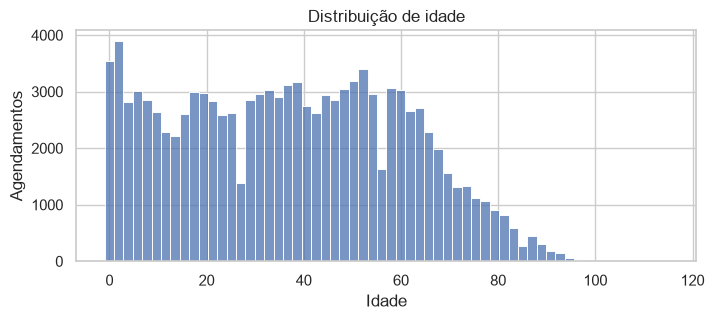

In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(df['Age'], bins=60, ax=ax)
ax.set(title='Distribuição de idade', xlabel='Idade', ylabel='Agendamentos')
plt.show()

### 1.6 Bairro

In [11]:
bairros = pd.DataFrame({'n': df['Neighbourhood'].value_counts(),
                        'taxa_falta': falta.groupby(df['Neighbourhood']).mean().round(3)})
print('Bairros distintos:', len(bairros))
print('Bairros com menos de 50 agendamentos:')
bairros[bairros['n'] < 50]

Bairros distintos: 81
Bairros com menos de 50 agendamentos:


,n,taxa_falta
Neighbourhood,,
AEROPORTO,8,0.125
ILHA DO BOI,35,0.086
ILHA DO FRADE,10,0.200
ILHAS OCEÂNICAS DE TRINDADE,2,1.000
PARQUE INDUSTRIAL,1,0.000


### 1.7 Datas e dias de espera

In [12]:
print('ScheduledDay:', sched.min(), '->', sched.max())
print('AppointmentDay:', appt.min(), '->', appt.max())
print('Horas distintas em AppointmentDay:', appt.dt.strftime('%H:%M:%S').unique())
print('Dias com consulta:', appt.dt.normalize().nunique())
appt.dt.day_name().value_counts()

ScheduledDay: 2015-11-10 07:13:56+00:00 -> 2016-06-08 20:07:23+00:00
AppointmentDay: 2016-04-29 00:00:00+00:00 -> 2016-06-08 00:00:00+00:00
Horas distintas em AppointmentDay: <StringArray>
['00:00:00']
Length: 1, dtype: str
Dias com consulta: 27


AppointmentDay
Wednesday    25867
Tuesday      25640
Monday       22715
Friday       19019
Thursday     17247
Saturday        39
Name: count, dtype: int64

In [13]:
espera = (appt.dt.normalize() - sched.dt.normalize()).dt.days
print(espera.describe())
print('Espera negativa:', (espera < 0).sum(), espera[espera < 0].value_counts().to_dict())
print('Mesmo dia:', (espera == 0).sum())
print('Taxa de falta (mesmo dia):', round(falta[espera == 0].mean(), 3))
print('Taxa de falta (com espera):', round(falta[espera > 0].mean(), 3))

count    110527.000000
mean         10.183702
std          15.254996
min          -6.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
dtype: float64
Espera negativa: 5 {-1: 4, -6: 1}
Mesmo dia: 38563
Taxa de falta (mesmo dia): 0.046
Taxa de falta (com espera): 0.285


### 1.8 A armadilha do SMS

Quem recebeu SMS parece faltar mais. Mas o SMS só vai para consultas com 3 ou mais dias de espera,
que já faltam mais. Comparando dentro desse grupo, o efeito se inverte.

In [14]:
print('SMS em consultas com espera <= 2 dias:', df.loc[espera <= 2, 'SMS_received'].sum())
print('Taxa de falta por SMS (todos):', falta.groupby(df['SMS_received']).mean().round(3).to_dict())
m = espera >= 3
print('Taxa de falta por SMS (espera >= 3 dias):', falta[m].groupby(df.loc[m, 'SMS_received']).mean().round(3).to_dict())

SMS em consultas com espera <= 2 dias: 0
Taxa de falta por SMS (todos): {0: 0.167, 1: 0.276}
Taxa de falta por SMS (espera >= 3 dias): {0: 0.327, 1: 0.276}


### 1.9 Resumo dos problemas

| Problema | Linhas | O que fazer (S2) |
|---|---|---|
| Dias de espera negativos | 5 | Remover |
| Idade negativa | 1 | Remover |
| Idade acima de 100 | 7 | Avaliar (4 são do mesmo paciente com 115) |
| Duplicatas sem `AppointmentID` | 618 | Decidir se remove; 14 grupos têm alvo divergente |
| `PatientId` como float, 5 com decimais | 5 | Converter para string |
| Datas como texto | todas | Converter para datetime |
| Nomes com erro / hífen | — | Renomear (`Hipertension`, `Handcap`, `No-show`) |
| `Handcap` é contagem, não binária | — | Manter como inteiro ou binarizar com cuidado |
| `SMS_received` confundido com espera | — | Controlar pelo tempo de espera nas análises |
| Bairros com poucos registros | ~7 | Agrupar em "outros" na modelagem |

## 2. S3 — EDA no treino, sem consultar o teste (#10–#12)

As seções anteriores documentam a auditoria inicial do dataset completo. A exploração abaixo usa apenas a partição de treino por paciente. Taxas são associações; o suporte acompanha cada estimativa.

In [ ]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from src.data import clean, load_raw
from src.features import build_features, add_patient_history
from src.models import split_by_patient
from src.analysis import rate_table
import pandas as pd
import matplotlib.pyplot as plt
all_data = add_patient_history(build_features(clean(load_raw(ROOT / 'data/raw/KaggleV2-May-2016.csv'))))
train_idx, test_idx = split_by_patient(all_data)
eda = all_data.iloc[train_idx].copy()


In [ ]:
eda['age_band'] = pd.cut(eda.age, [-1, 5, 12, 18, 35, 60, 120])
eda['waiting_band'] = pd.cut(eda.waiting_days, [-1, 0, 2, 7, 14, 30, 60, 365])
for column in ['age_band', 'gender', 'neighbourhood', 'bolsa_familia', 'hypertension', 'diabetes', 'alcoholism', 'handicap', 'waiting_band', 'weekday']:
    table = rate_table(eda, column)
    display(table)
    table.set_index(column)['rate'].plot.bar(figsize=(12, 3), title=f'Taxa de falta: {column}')
    plt.ylabel('Taxa de falta')
    plt.show()

### Histórico do paciente (#9)

Consultas no próprio dia do agendamento ficam fora do histórico, pois não há horário de atendimento. Ausência de histórico observável não significa ausência de consultas anteriores na vida do paciente.

In [ ]:
eda['has_history'] = eda.previous_appointments.gt(0)
display(eda.groupby(['has_history', 'previous_no_shows'], observed=True).no_show.agg(appointments='size', rate='mean'))
print('Cobertura do histórico:', eda.has_history.mean())

### SMS condicionado à antecedência

Comparar dentro das faixas reduz a mistura entre antecedências, mas não identifica efeito causal do SMS.

In [ ]:
display(eda.groupby(['waiting_band', 'sms_received'], observed=True).no_show.agg(appointments='size', no_shows='sum', rate='mean'))

### Correlações e seleção inicial (#12)

Spearman apenas para atributos numéricos. Bairro, gênero e dia da semana usam one-hot na modelagem; não recebem códigos ordinais arbitrários. Correlação marginal baixa não é motivo suficiente para excluir um atributo.

In [ ]:
from src.features import NUMERIC_FEATURES, HISTORY_FEATURES
import seaborn as sns
corr = eda[NUMERIC_FEATURES + HISTORY_FEATURES + ['no_show']].corr(method='spearman')
display(corr['no_show'].sort_values())
plt.figure(figsize=(11, 8))
sns.heatmap(corr, vmin=-1, vmax=1, cmap='coolwarm')
plt.show()

Mantemos os atributos cadastrais, espera, dia da semana e histórico como candidatos. Excluímos identificadores, SMS, datas brutas e `same_day` (redundante com espera zero). Histórico é uma hipótese inicial, com cobertura limitada nesta janela; validar ganho por ablação na S4. Consulte [resultados e respostas de negócio](../docs/sprints-2-3.md).